## Challenge 01 (September-October 2026): Expected Credit Loss

This challenge wants to solve the next query:

"Good morning, 

We need to calculate the expected loss for the new portfolio we just acquired. These results will be used for provisions and must be validated by the regulator, so we need to be conservative to avoid potential penalties.

We need the data ready for the Committee meeting on October 25. We’ve attached the data we have on the portfolio.

Best regards, 

Big Boss"

The data used comes from [Credit Scoring | Lending Club Loan Data Cleared Kaggle page](https://www.kaggle.com/datasets/db0boy/lending-club-loan-data-cleared/data) and has two files: `X.csv` with the variables for modeling and `target.csv` with the binary target

In [1]:
# Import main libraries
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

# Set seed for models
SEED = 42
np.random.seed(SEED)

# Set styles
pd.set_option('display.float_format', lambda x: '%.3f' % x) 
sns.set_style("whitegrid")


In [ ]:
# Transform csv to parquet 
# X = pd.read_csv("data/X.csv")
# X.to_parquet("data/X.parquet", index=False)

# y = pd.read_csv("data/target.csv")
# y.to_parquet("data/target.parquet", index=False)

In [ ]:
# Read files
X = pd.read_parquet("data/X.parquet")
X.head()

,funded_amnt,interest_rate,monthly_payment,grade,emp_title,emp_length,home_ownership_status,annual_income,verification_status,loan_purpose,...,num_inq_in_12mths,mths_since_recent_bankcard_delinq,mths_since_recent_revol_delinq,disbursement_method,loan_term_months,issue_date_month,issue_date_year,region_code,earliest_cr_line_month,earliest_cr_line_year
0,2500,13.56,84.92,C1,Chef,10+ years,RENT,55000.0,Not Verified,debt_consolidation,...,2,NaN,NaN,Cash,36,Dec,2018,1,Apr,2001
1,30000,18.94,777.23,D2,Postmaster,10+ years,MORTGAGE,90000.0,Source Verified,debt_consolidation,...,2,NaN,NaN,Cash,60,Dec,2018,7,Jun,1987
2,5000,17.97,180.69,D1,Administrative,6 years,MORTGAGE,59280.0,Source Verified,debt_consolidation,...,0,NaN,NaN,Cash,36,Dec,2018,4,Apr,2011
3,4000,18.94,146.51,D2,IT Supervisor,10+ years,MORTGAGE,92000.0,Source Verified,debt_consolidation,...,3,NaN,NaN,Cash,36,Dec,2018,9,Feb,2006
4,30000,16.14,731.78,C4,Mechanic,10+ years,MORTGAGE,57250.0,Not Verified,debt_consolidation,...,0,NaN,NaN,Cash,60,Dec,2018,2,Dec,2000


In [ ]:
target = pd.read_parquet("data/target.parquet")
target.head()

,y
0,0
1,0
2,0
3,0
4,0


In [4]:
# Information of variables for modeling
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 2139643 entries, 0 to 2139642
Data columns (total 45 columns):
 #   Column                              Dtype  
---  ------                              -----  
 0   funded_amnt                         int64  
 1   interest_rate                       float64
 2   monthly_payment                     float64
 3   grade                               str    
 4   emp_title                           str    
 5   emp_length                          str    
 6   home_ownership_status               str    
 7   annual_income                       float64
 8   verification_status                 str    
 9   loan_purpose                        str    
 10  addr_state                          str    
 11  dept_paym_income_ratio              float64
 12  num_30+_delinq_in_2yrs              int64  
 13  num_inq_in_6mths                    int64  
 14  mths_since_last_delinq              float64
 15  num_open_credit_lines               int64  
 16  num_derogat

## Variable descriptions

Descriptions published on the [Credit Scoring | Lending Club Loan Data Cleared Kaggle page](https://www.kaggle.com/datasets/db0boy/lending-club-loan-data-cleared/data) for the variables in X.csv.

| Variable | Description on Kaggle |
|---|---|
| funded_amnt | The total amount committed to that loan at that point in time |
| interest_rate | Interest Rate on the loan |
| monthly_payment | The monthly payment owed by the borrower if the loan originates |
| grade | grade from C1 to A5, from worse to best respectively |
| emp_title | The job title supplied by the Borrower when applying for the loan |
| emp_length | Employment length in years |
| home_ownership_status | The home ownership status provided by the borrower during registration |
| annual_income | The self-reported annual income provided by the borrower during registration |
| verification_status | Indicates if income was verified by LC, not verified, or if the income source was verified |
| loan_purpose | A category provided by the borrower for the loan request |
| addr_state | The state provided by the borrower in the loan application |
| dept_paym_income_ratio | A ratio calculated using the borrower’s total monthly debt payments on the total debt obligations, excluding mortgage and the requested LC loan, divided by the borrower’s self-reported monthly income |
| num_30+_delinq_in_2yrs | The number of 30+ days past-due incidences of delinquency |
| num_inq_in_6mths | The number of inquiries in past 6 months (excluding auto and mortgage inquiries) |
| mths_since_last_delinq | The number of months since the borrower’s last delinquency |
| num_open_credit_lines | The number of open credit lines in the borrower’s credit file |
| num_derogatory_pub_rec | Number of derogatory public records |
| total_credit_revolving_bal | Total credit revolving balance |
| used_credit_share | Revolving line utilization rate, or the amount of credit the borrower is using relative to all assets |
| tot_num_credit_lines | The total number of credit lines currently in the borrower’s credit file |
| initial_list_status | The initial listing status of the loan |
| remaining_princ_for_tot_amnt_fund | Remaining outstanding principal for total amount funded |
| paym_rec_for_tot_amnt_fund | Payments received to date for total amount funded |
| princ_rec | Principal received to date |
| interest_rec | Interest received to date |
| late_fees_rec | Late fees received to date |
| num_open_trades_in_6mths | Number of open trades in last 6 months |
| num_installment_acc_op_in_12mths | Number of installment accounts opened in past 12 months |
| num_installment_acc_op_in_24mths | Number of installment accounts opened in past 24 months |
| mths_since_last_installment_acc_op | Months since most recent installment accounts opened |
| num_rev_trades_op_in_12mths | Number of revolving trades opened in past 12 months |
| num_rev_trades_op_in_24mths | Number of revolving trades opened in past 24 months |
| max_bal_owed | Maximum current balance owed on all revolving accounts |
| bal_to_cred_lim | Balance to credit limit on all trades |
| num_inq | Number of personal finance inquiries |
| num_inq_in_12mths | Number of credit inquiries in past 12 months |
| mths_since_recent_bankcard_delinq | Months since most recent bankcard delinquency |
| mths_since_recent_revol_delinq | Months since most recent revolving delinquency |
| disbursement_method | The method by which the borrower receives their loan |
| loan_term_months | Loan duration in months |
| issue_date_month | The month which the loan was funded |
| issue_date_year | The year which the loan was funded |
| region_code | Region code, ranging from "0" in the Northeast (e.g. Massachusetts, Connecticut) to "9" in the West (e.g. California, Alaska). |
| earliest_cr_line_month | The month the borrower’s earliest reported credit line was opened |
| earliest_cr_line_year | The year the borrower’s earliest reported credit line was opened |


In [5]:
string_var = [var for var in X.columns if X[var].dtype == 'string']
numeric_var = [var for var in X.columns if X[var].dtype == 'int64' or X[var].dtype == 'float64']
print(string_var)
print(numeric_var)
print(f"Number of string variables: {len(string_var)}")
print(f"Number of numeric variables: {len(numeric_var)}")
print("All variables are categorized as string or numeric?", len(string_var) + len(numeric_var) == X.shape[1])

['grade', 'emp_title', 'emp_length', 'home_ownership_status', 'verification_status', 'loan_purpose', 'addr_state', 'initial_list_status', 'disbursement_method', 'issue_date_month', 'earliest_cr_line_month']
['funded_amnt', 'interest_rate', 'monthly_payment', 'annual_income', 'dept_paym_income_ratio', 'num_30+_delinq_in_2yrs', 'num_inq_in_6mths', 'mths_since_last_delinq', 'num_open_credit_lines', 'num_derogatory_pub_rec', 'total_credit_revolving_bal', 'used_credit_share', 'tot_num_credit_lines', 'remaining_princ_for_tot_amnt_fund', 'paym_rec_for_tot_amnt_fund', 'princ_rec', 'interest_rec', 'late_fees_rec', 'num_open_trades_in_6mths', 'num_installment_acc_op_in_12mths', 'num_installment_acc_op_in_24mths', 'mths_since_last_installment_acc_op', 'num_rev_trades_op_in_12mths', 'num_rev_trades_op_in_24mths', 'max_bal_owed', 'bal_to_cred_lim', 'num_inq', 'num_inq_in_12mths', 'mths_since_recent_bankcard_delinq', 'mths_since_recent_revol_delinq', 'loan_term_months', 'issue_date_year', 'region_co

In [6]:
# Checking the number of unique values in string variables
X[string_var].nunique().sort_values(ascending=False)

emp_title                 496831
addr_state                    51
grade                         35
loan_purpose                  14
issue_date_month              12
earliest_cr_line_month        12
emp_length                    11
home_ownership_status          4
verification_status            3
disbursement_method            2
initial_list_status            2
dtype: int64

This analysis shows that some of the string variables can be tuned into numeric variables: 
- Some of then represent months, which can be turned into their numerical representation
- Some of then are binary, which is easily coded keeping just one variable, whereas other have 3 or 4 possible values, which cane be handled using techniques as OHE


In [7]:
# Checking the number of unique values in numeric variables after removing spaces and converting to lower case
X["emp_title"] = X["emp_title"].str.lower().str.strip()
X["emp_title"].nunique()

400000

In [8]:
X['emp_title'].value_counts().head(10)


emp_title
manager             43698
teacher             43694
owner               31925
registered nurse    22142
driver              21081
supervisor          21039
sales               18135
rn                  16352
project manager     13210
office manager      13196
Name: count, dtype: int64

In [9]:
X['emp_title'].value_counts().tail(10)  

emp_title
ambulatory administration supervisor    1
dir. of plant ops                       1
shipping/loader                         1
raw/finish perator technician           1
community protection and home care      1
financial biller/collections            1
avp, account manager                    1
vault clerk and home decor sales        1
instructor / lab coordinator            1
sales, estimating & design              1
Name: count, dtype: int64

Although some values are representative, there are some that are just used one as some are very specific roles

In [10]:
X['addr_state'].unique()

<StringArray>
['NY', 'LA', 'MI', 'WA', 'MD', 'IN', 'IL', 'FL', 'CT', 'GA', 'UT', 'NC', 'KY',
 'OH', 'AR', 'OK', 'CA', 'WV', 'SC', 'PA', 'KS', 'AL', 'VA', 'MO', 'AZ', 'TX',
 'NM', 'CO', 'RI', 'WI', 'NJ', 'TN', 'MA', 'NE', 'MN', 'NH', 'OR', 'VT', 'DC',
 'NV', 'MS', 'ID', 'ND', 'DE', 'ME', 'HI', 'AK', 'WY', 'MT', 'SD', 'IA']
Length: 51, dtype: str

This variable represents the 51 states of USA so it can be coded to integer labels if the model can't handle string variables

In [11]:
X['grade'].unique()

<StringArray>
['C1', 'D2', 'D1', 'C4', 'C3', 'C2', 'D5', 'B3', 'A4', 'B5', 'D4', 'E1', 'E4',
 'B4', 'D3', 'A1', 'B2', 'B1', 'F5', 'C5', 'A5', 'E3', 'E5', 'A2', 'A3', 'E2',
 'F4', 'G1', 'G2', 'F2', 'F1', 'F3', 'G4', 'G3', 'G5']
Length: 35, dtype: str

The variable `grade` reprents a categorization of letter labels, from A to G, which each has a level subcategorization from 1 to 5. This representation can easily be turned into a ordered numerical label that would be easier for the model and it allows algorithms which can't handle string variables

In [12]:
X['loan_purpose'].unique()

<StringArray>
['debt_consolidation',        'credit_card',              'house',
              'other',           'vacation',                'car',
   'home_improvement',     'small_business',     'major_purchase',
            'medical',   'renewable_energy',             'moving',
            'wedding',        'educational']
Length: 14, dtype: str

This variable reprents a categorization into 14 possible purpose of the loan, including a category `other` which helps to not increasing the number of possible values

In [13]:
X['emp_length'].unique()

<StringArray>
['10+ years',   '6 years',   '4 years',  '< 1 year',   '2 years',   '9 years',
   '5 years',   '3 years',   '7 years',    '1 year',         nan,   '8 years']
Length: 12, dtype: str

The possible values for this variable go from less than a year to 9 years plus 10 years or more and a NaN value that has to be studied as this variable represents the employment length in years, so it could be for instance that they do not have any job or they are retired. However, this variable is also easy to code into a numeric variable just using the number of years and using other numbers for some possible values

In [14]:
def plot_hist_boxplots(df, var, bins=10):
    """
    Function to plot histogram and boxplot for a given variable in a dataframe eliminating missing values.

    Parameters:
    df (pd.DataFrame): The input dataframe containing the variable.
    var (str): The name of the variable to plot.
    bins (int): The number of bins for the histogram. Default is 10.

    Returns:
    None
    """
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Histogram
    axes[0].hist(df[var].dropna(), bins=bins, color='skyblue', edgecolor='black')
    axes[0].set_title(f'Histogram of {var}')
    axes[0].set_xlabel(var)
    axes[0].set_ylabel('Frequency')

    # Boxplot
    axes[1].boxplot(df[var].dropna())
    axes[1].set_title(f'Boxplot of {var}')
    axes[1].set_xlabel(var)
    axes[1].set_ylabel('')
    plt.tight_layout()
    plt.show()


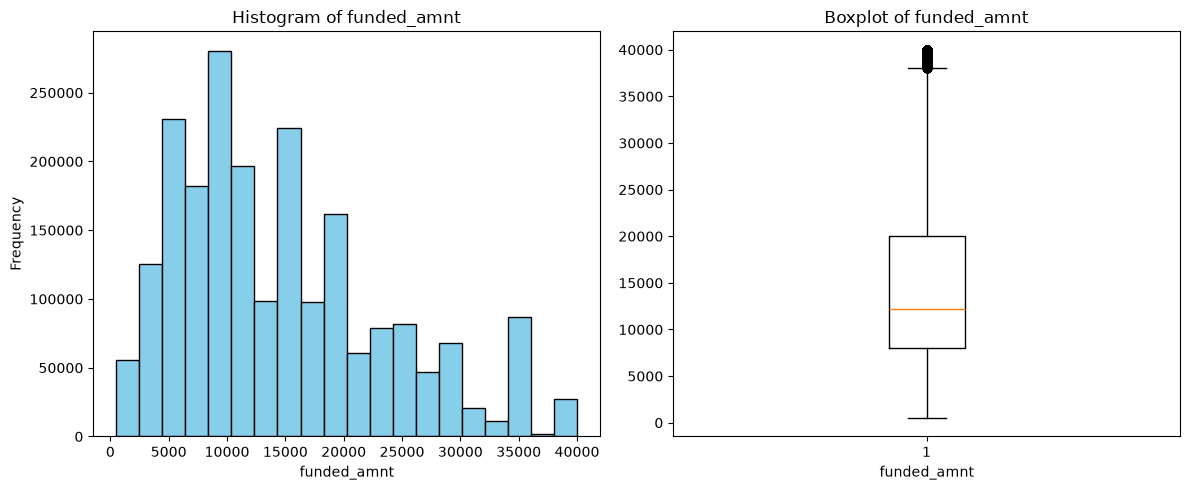

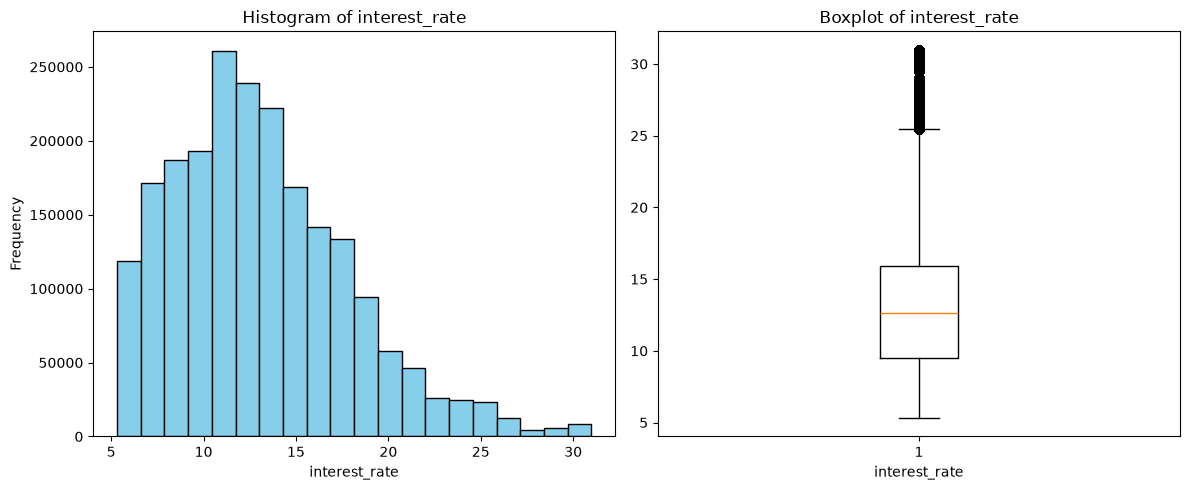

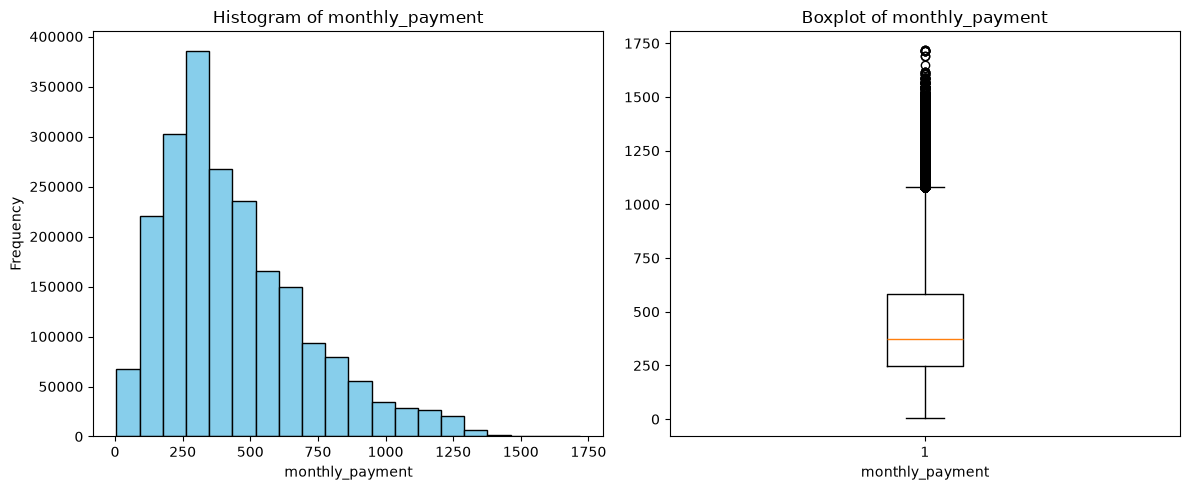

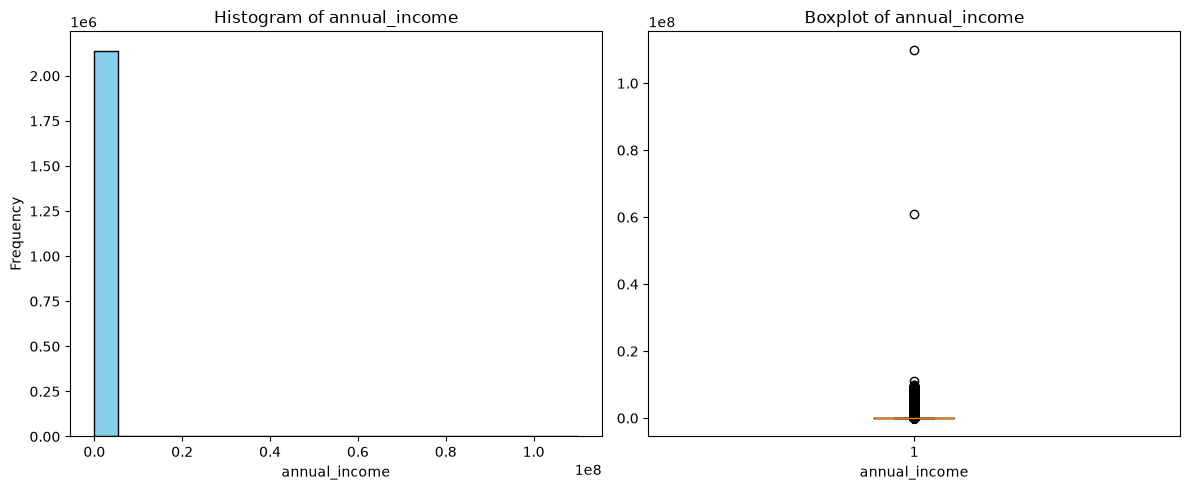

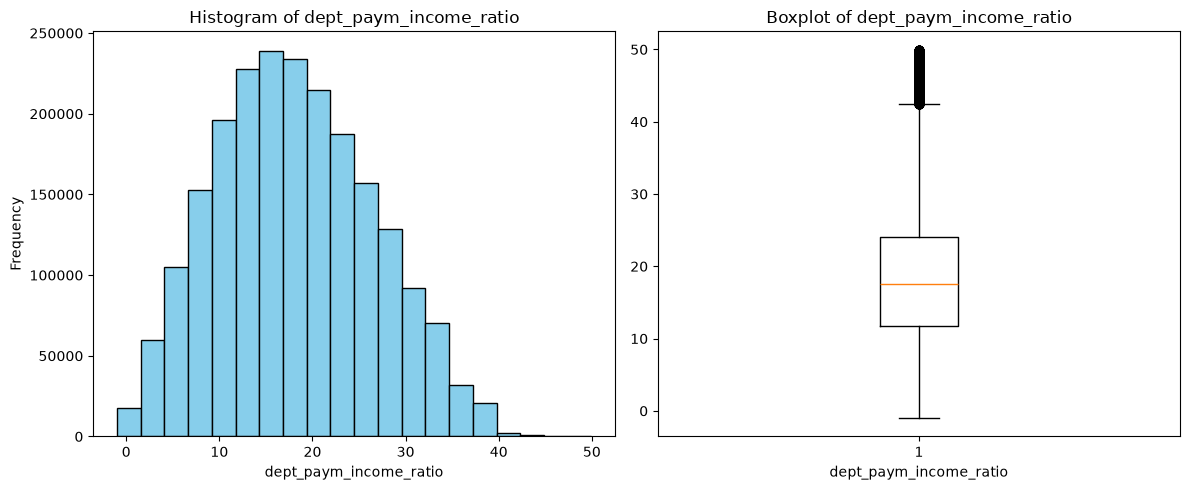

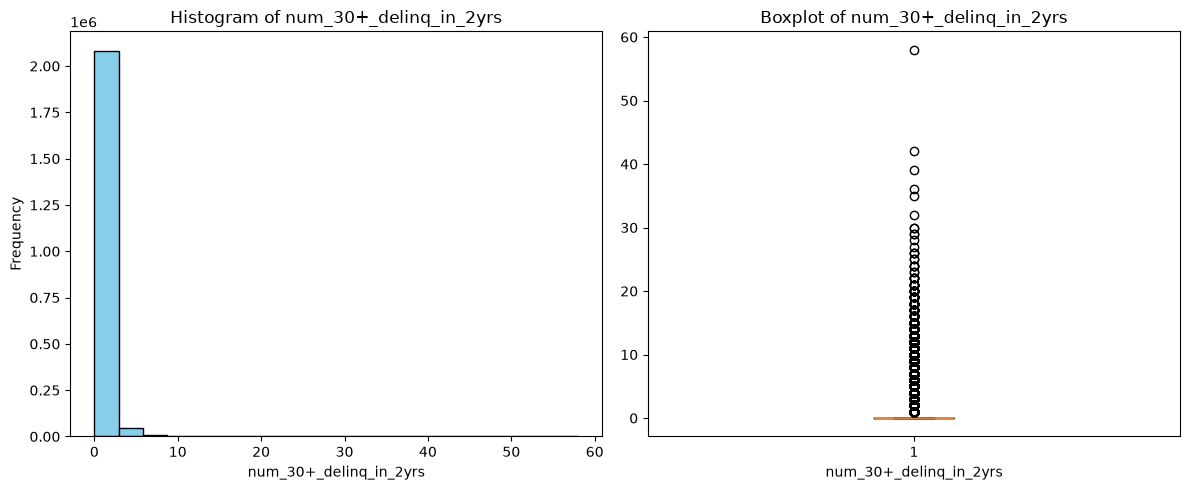

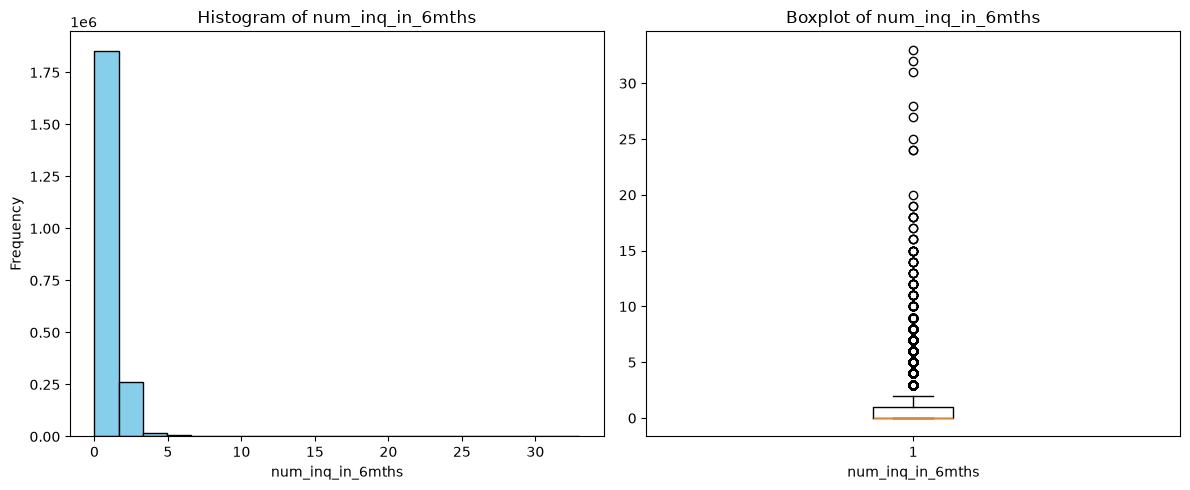

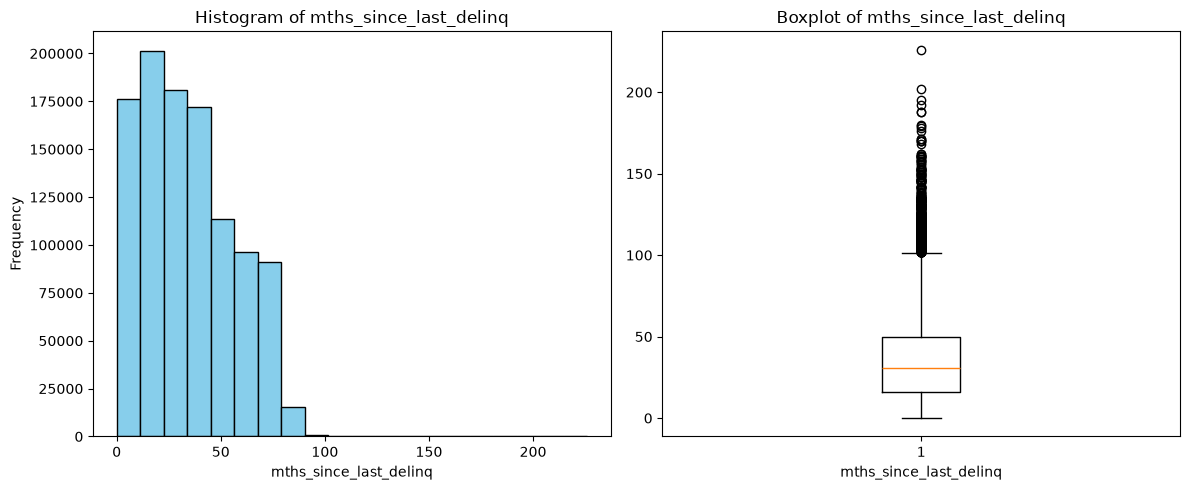

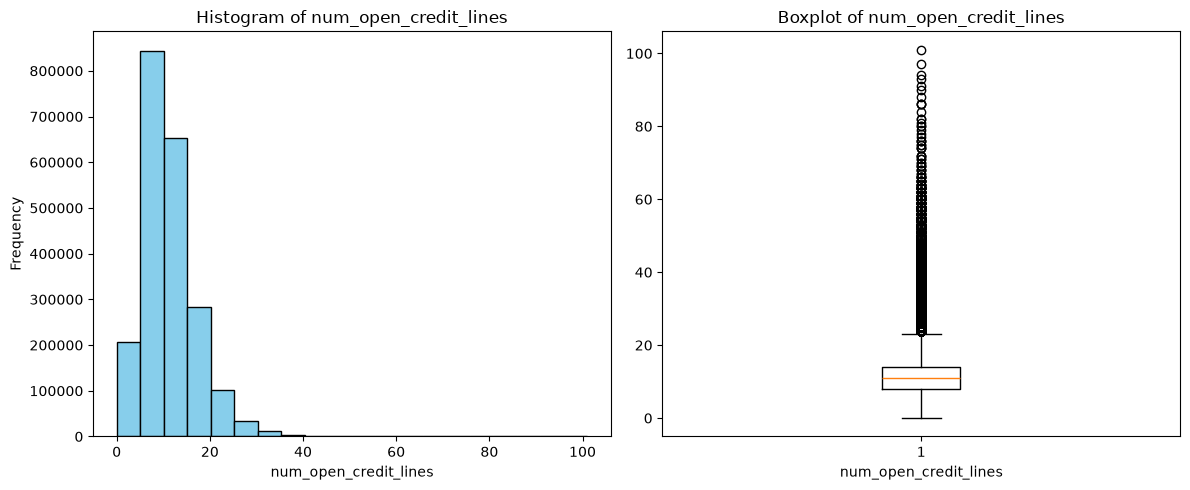

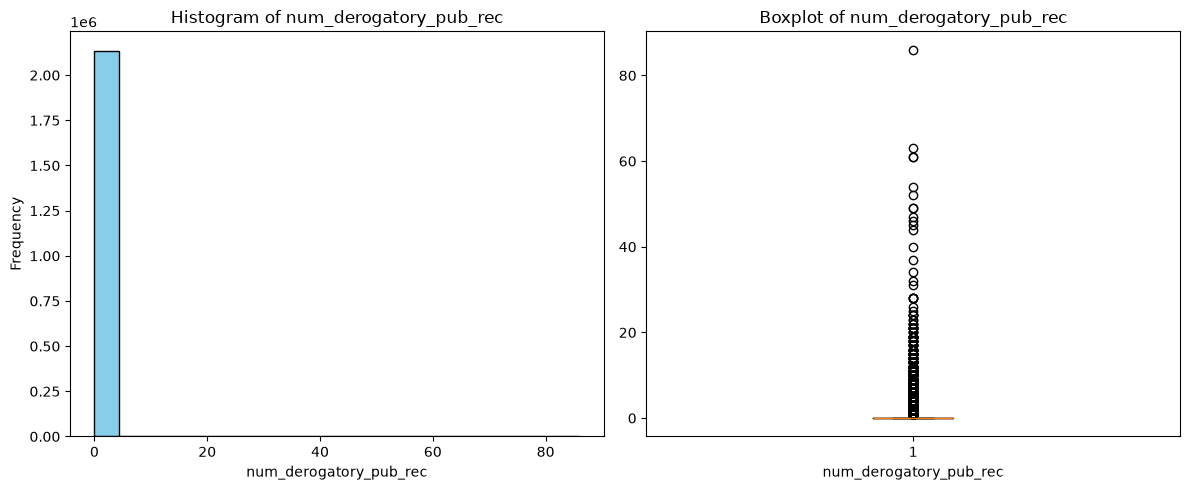

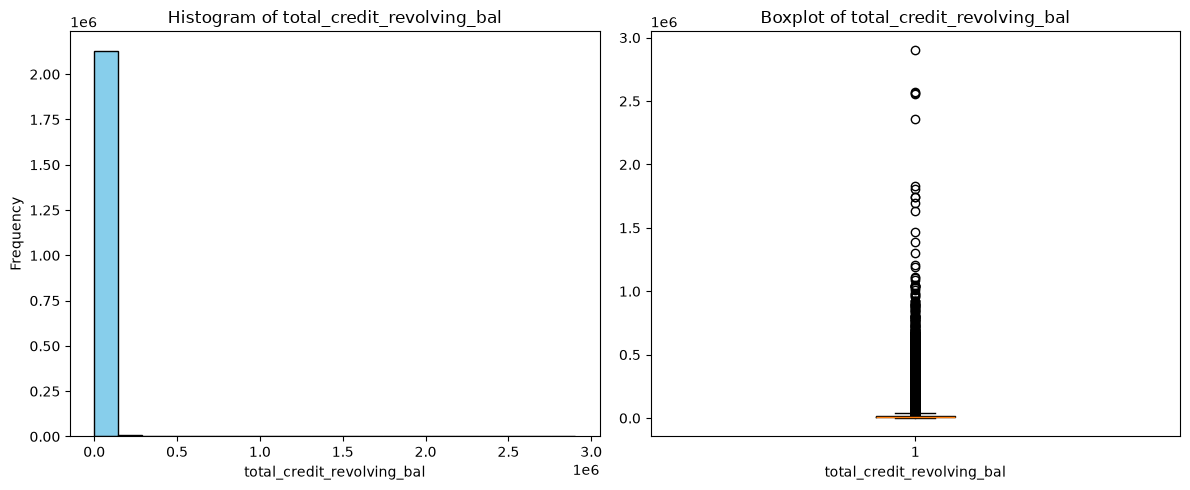

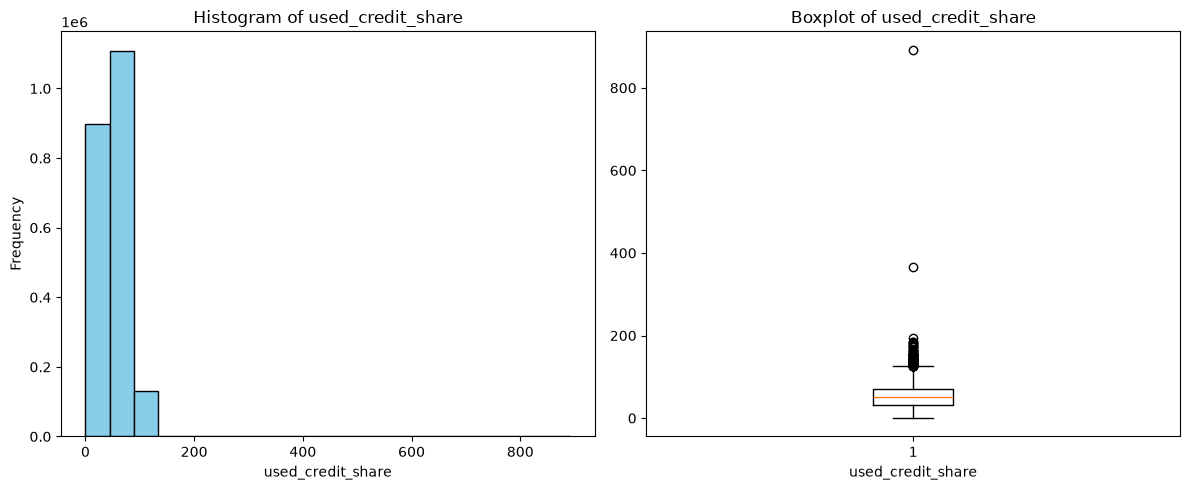

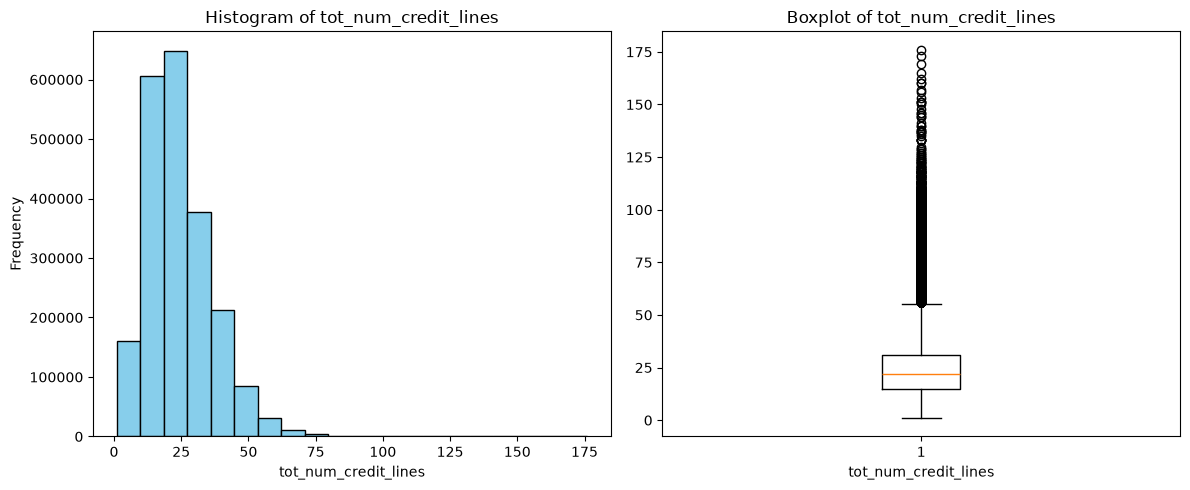

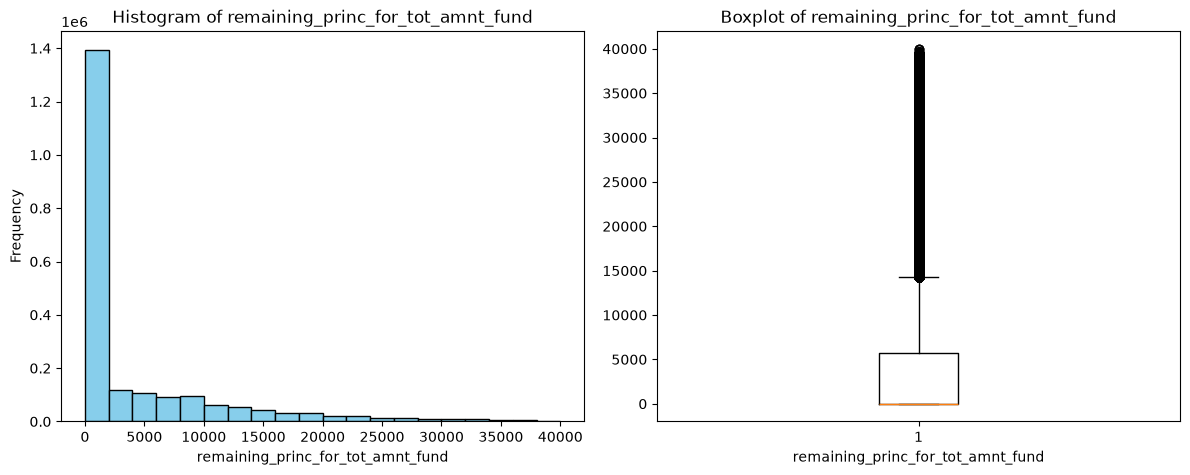

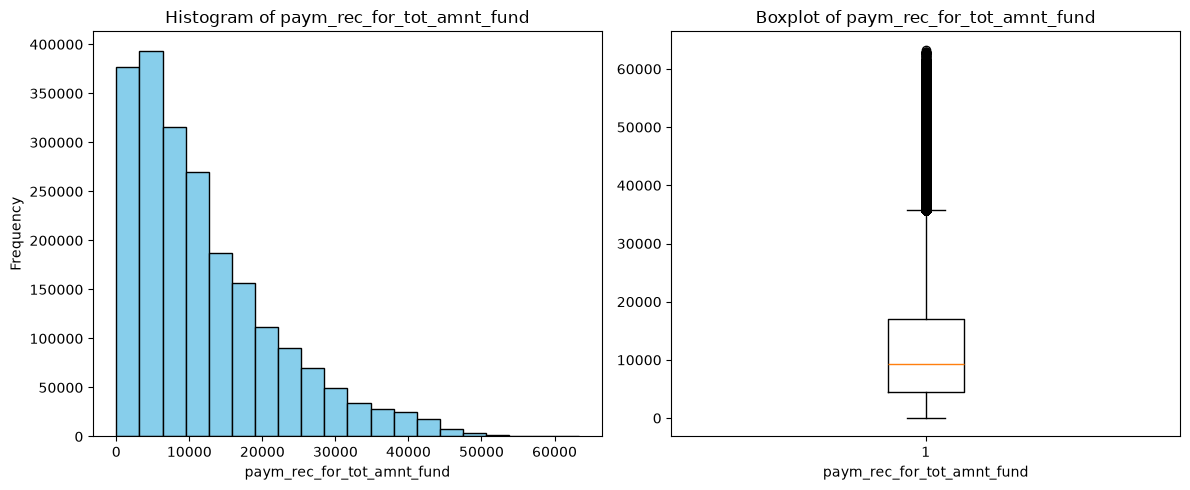

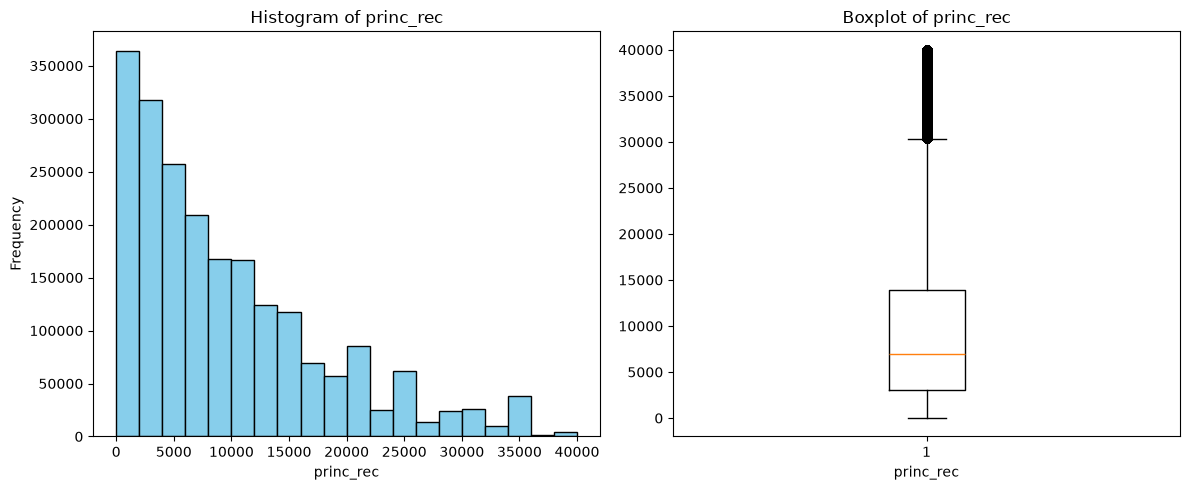

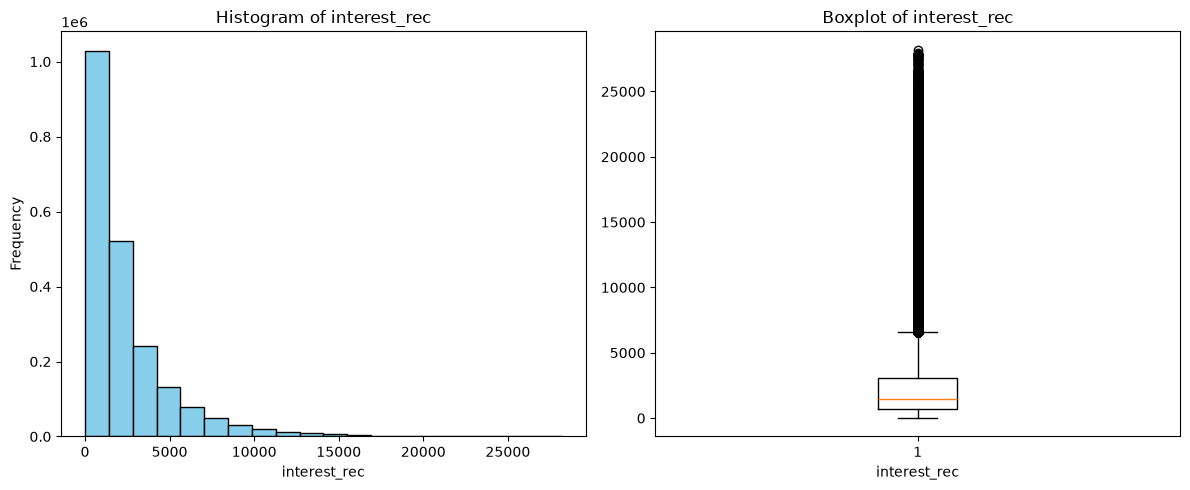

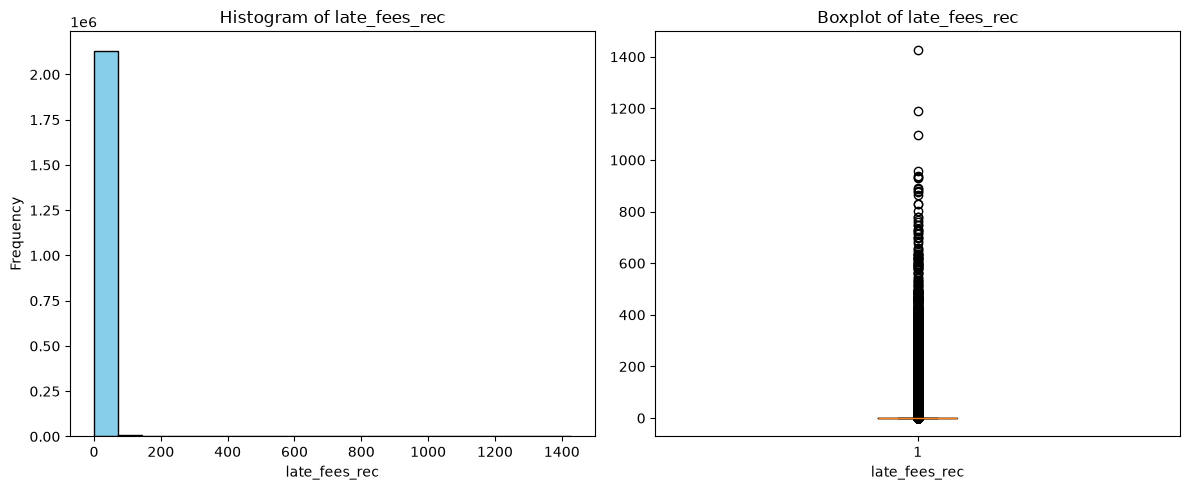

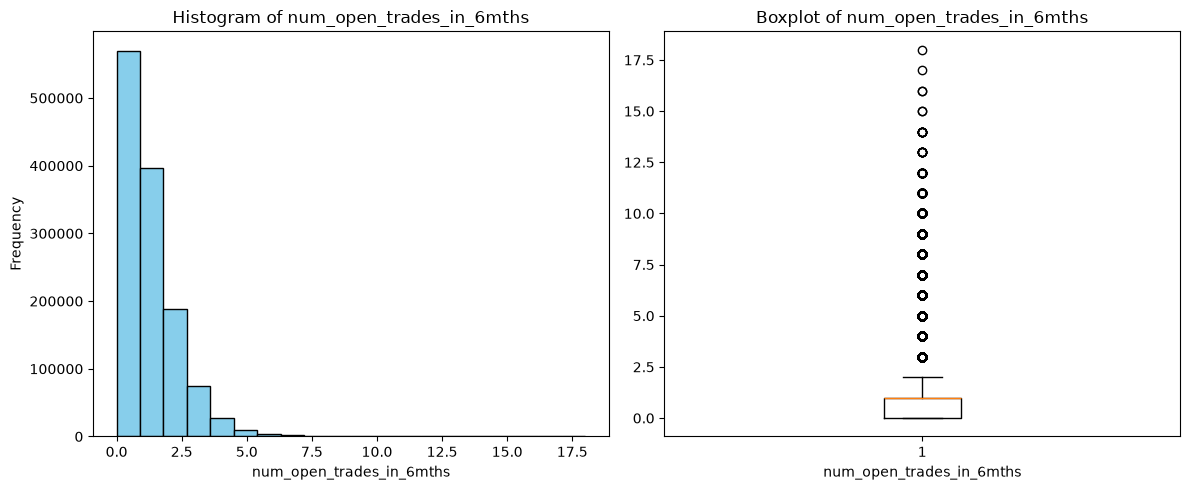

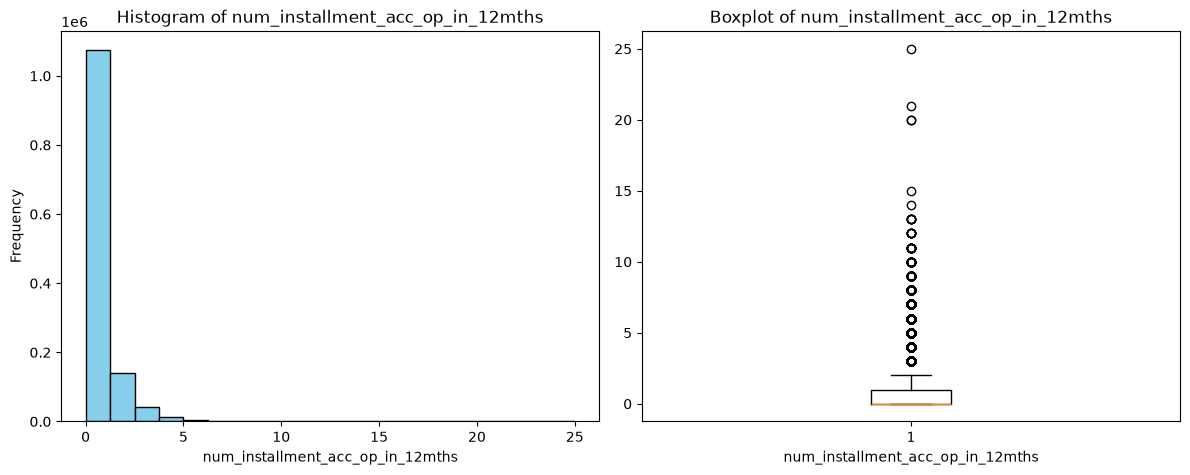

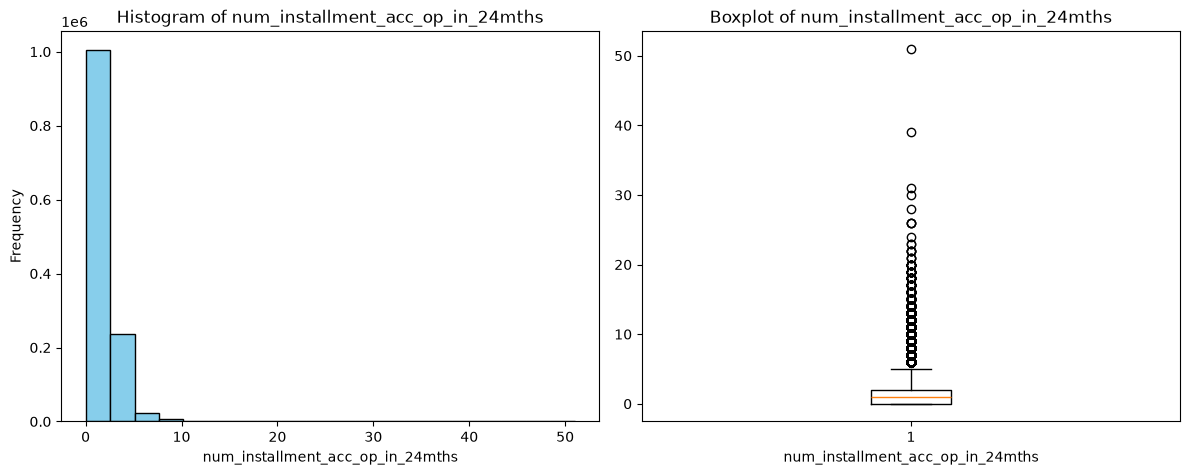

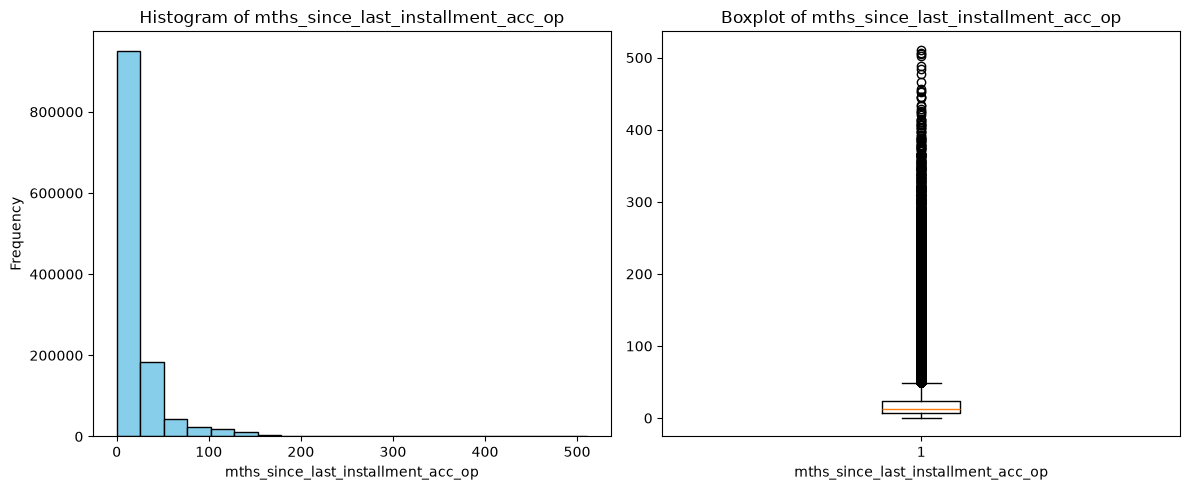

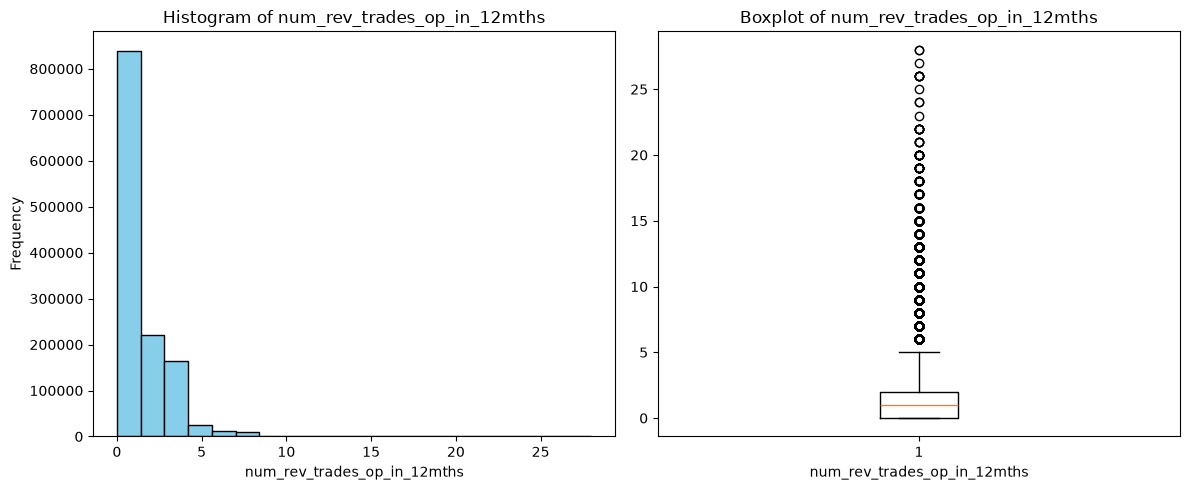

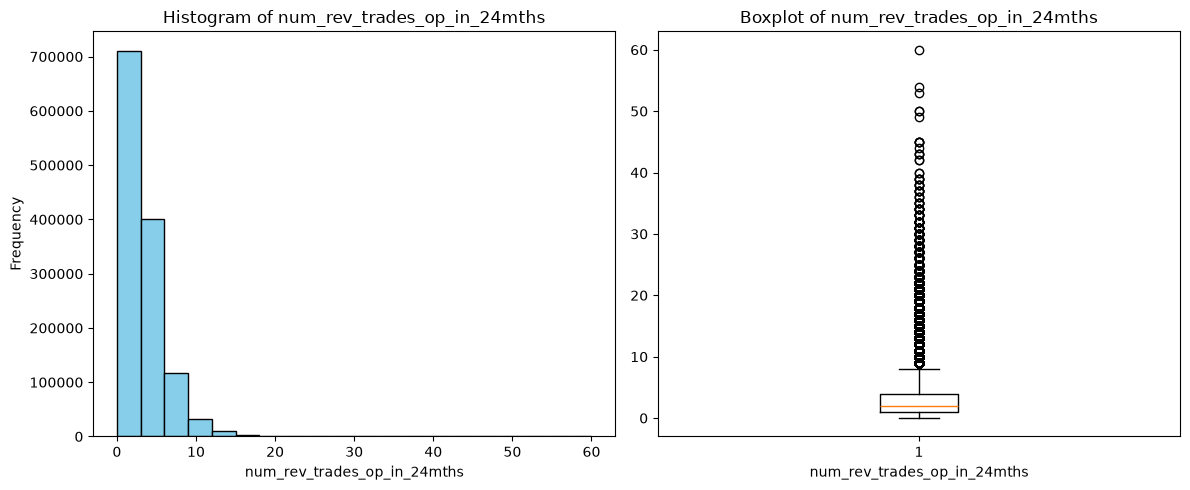

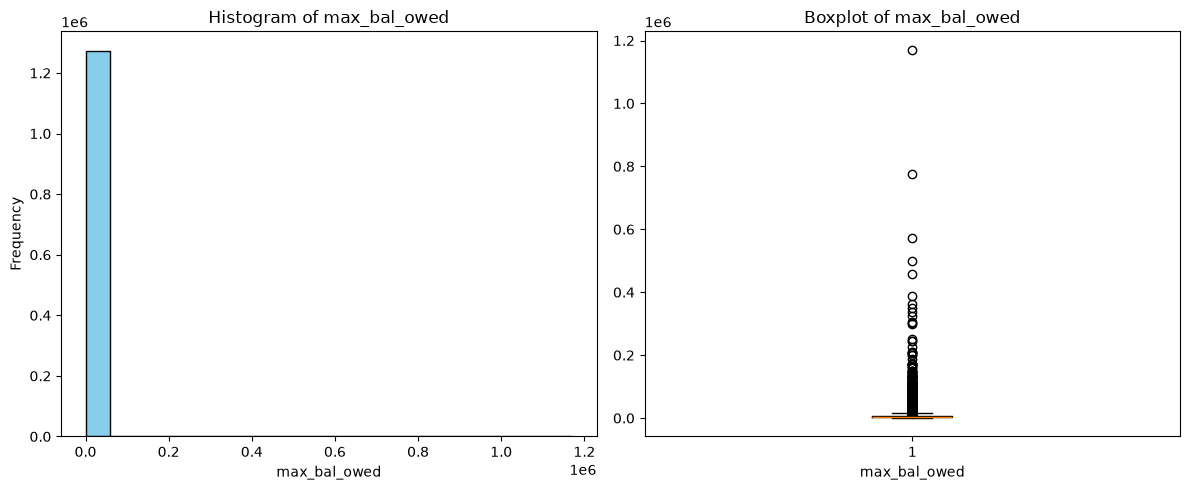

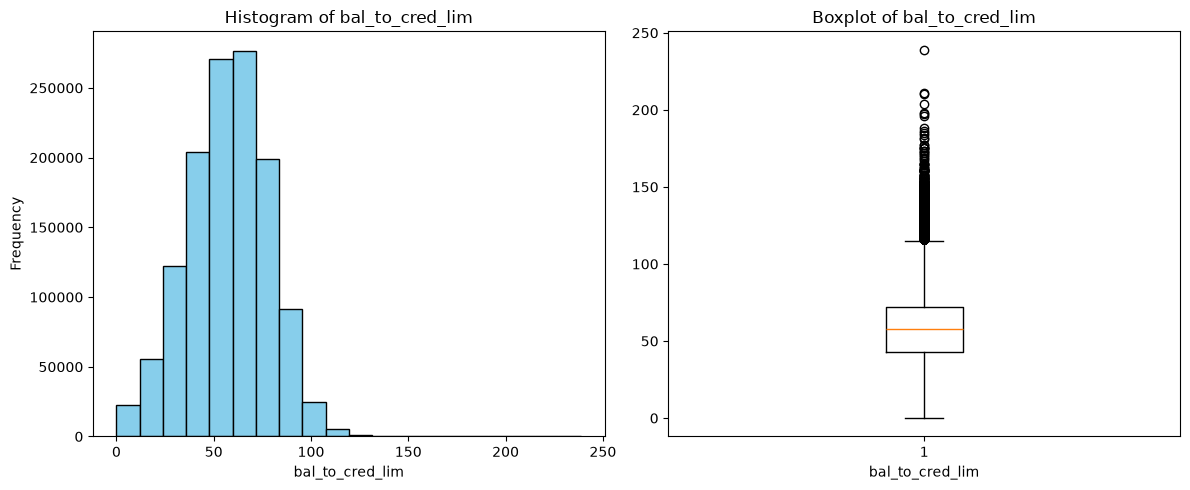

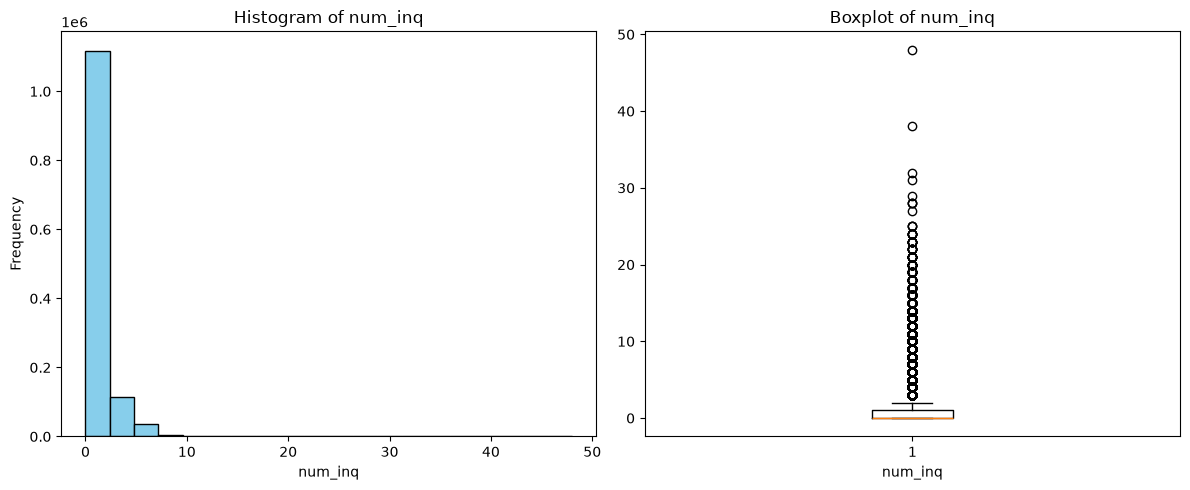

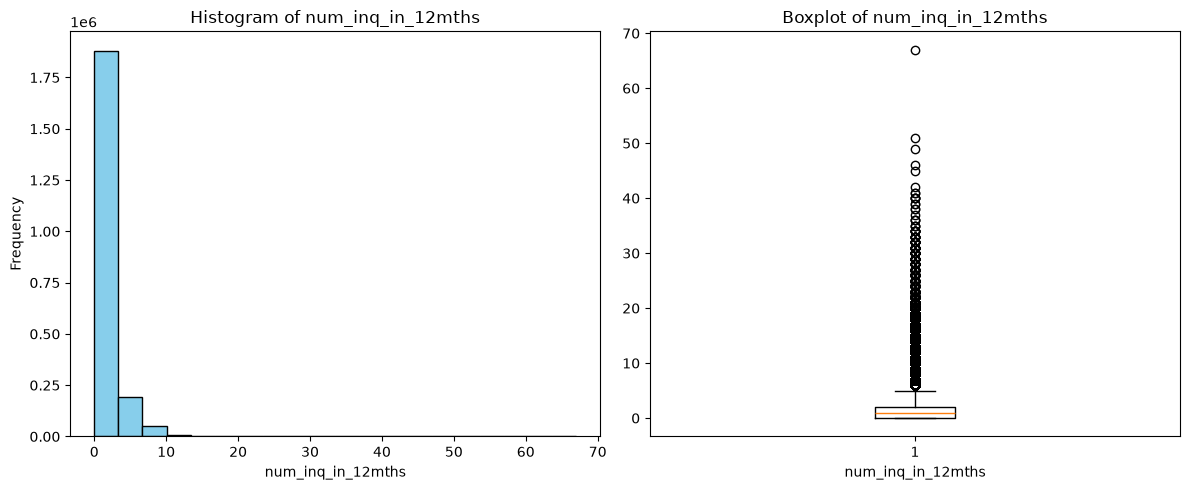

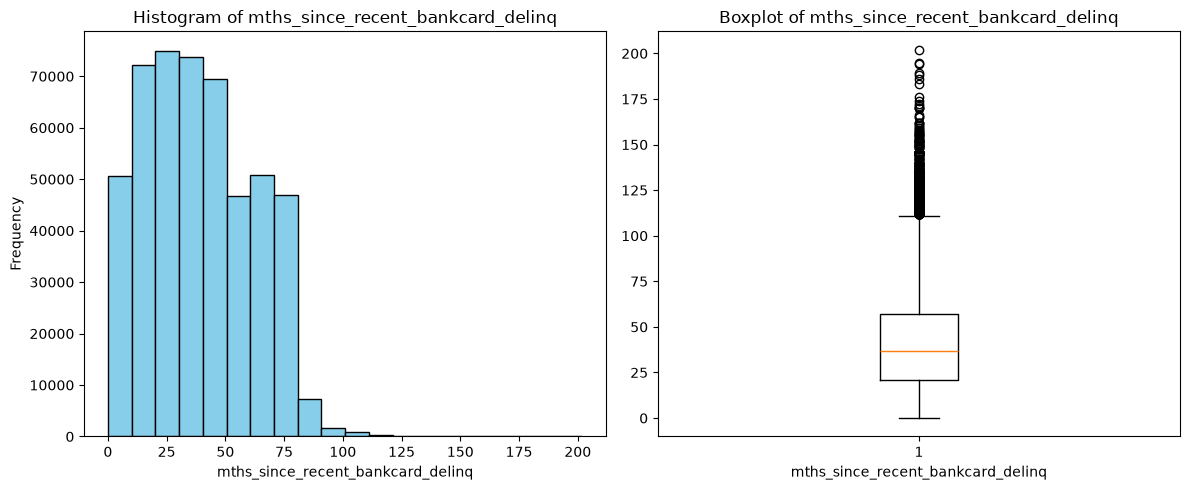

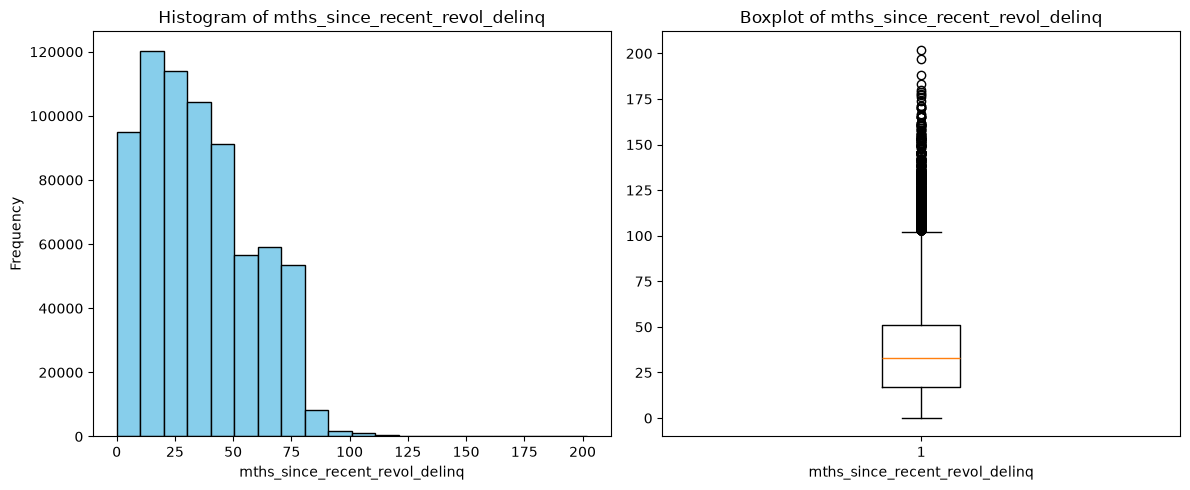

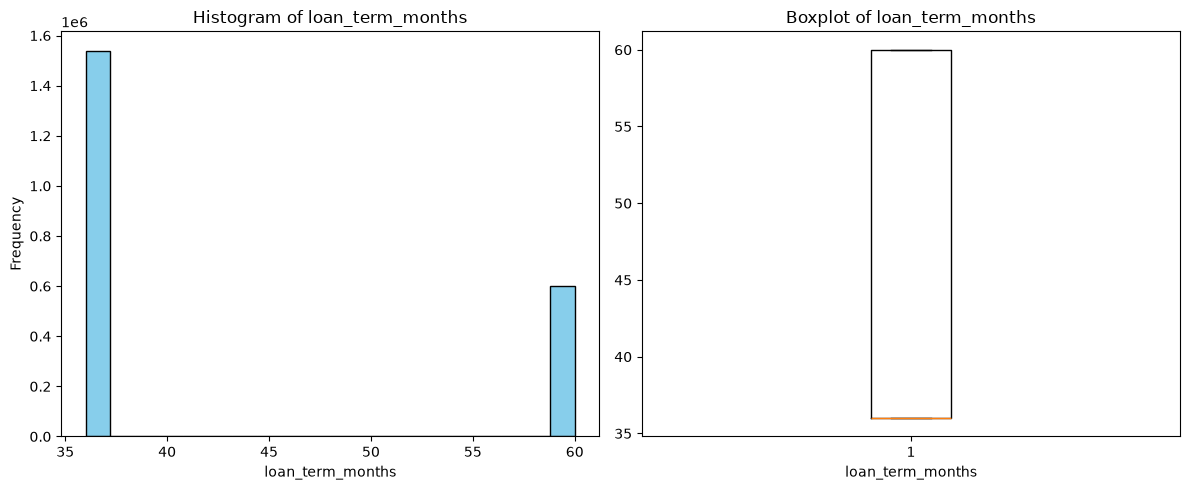

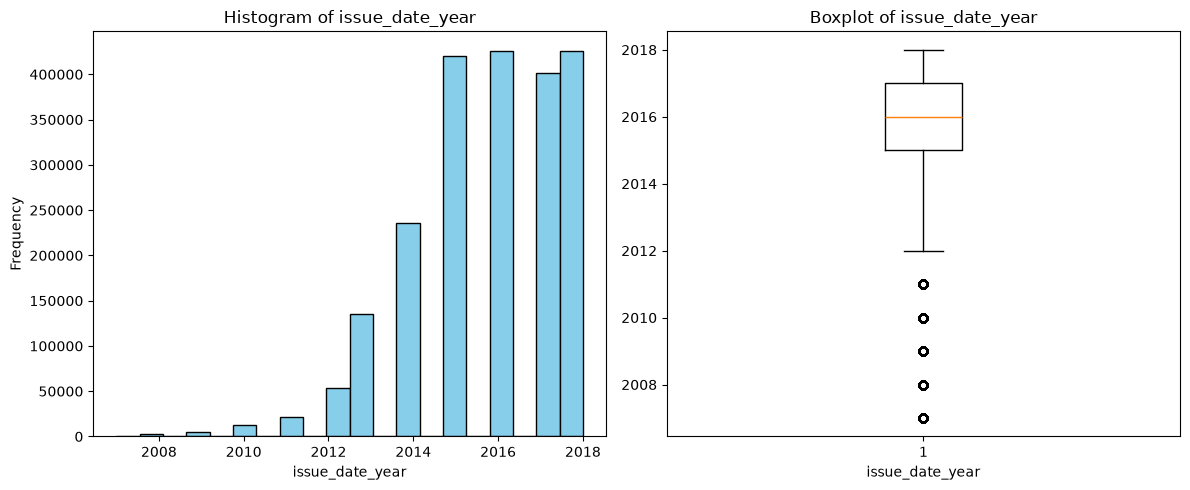

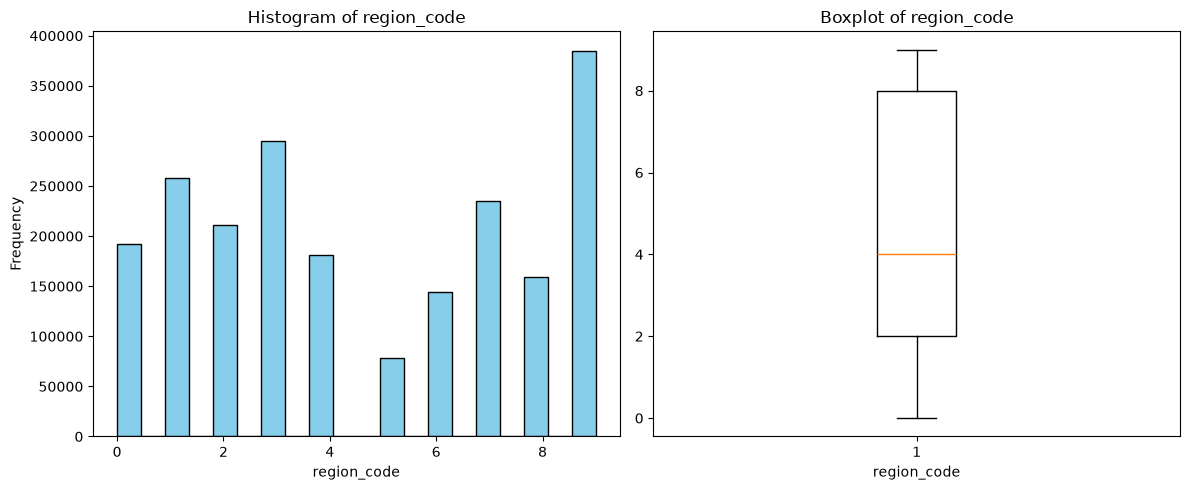

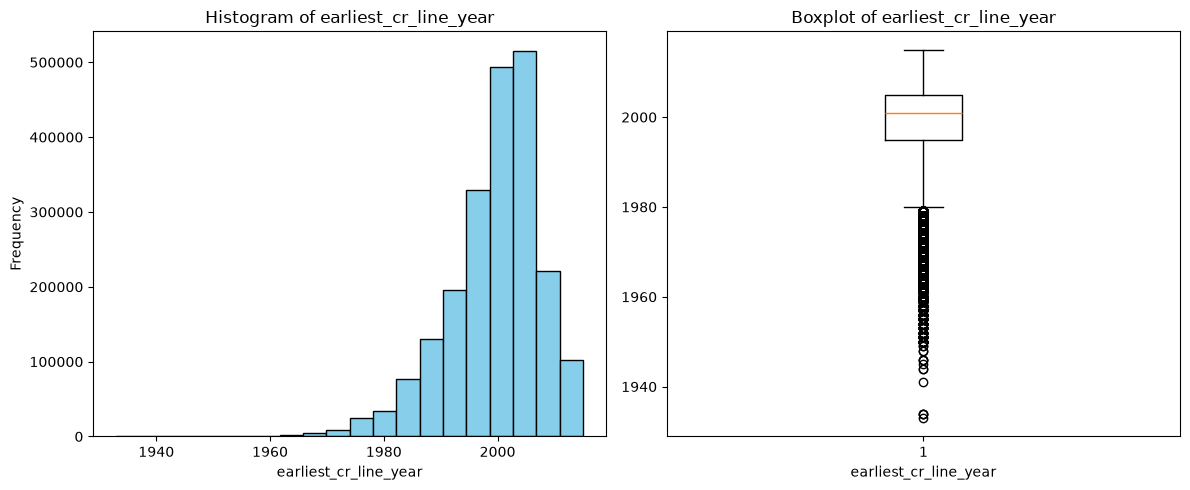

In [15]:
for var in numeric_var:
    plot_hist_boxplots(X, var, bins=20)

### Key takeaways from Histograms and Boxplots

- Most monetary and count variables have upper-tail outliers and right-skewed distributions. This is especially visible for `annual_income`, `total_credit_revolving_bal`, `max_bal_owed`, and the repayment-related variables. These extreme values stretch the plots and make the central range harder to read. Check unusual observations before treating them as errors or removing them; medians, percentiles, and log-scaled plots can help describe these distributions.

- Many count variables are concentrated at zero or at low values, including `num_30+_delinq_in_2yrs`, `num_derogatory_pub_rec`, and recent inquiry and account-opening counts. Their long tails show that a small number of borrowers have much higher counts than the majority. These variables are discrete counts, even when stored as numeric values.

- The numeric variables do not all have unimodal distributions. `loan_term_months` has two distinct values, 36 and 60 months, so it is a discrete two-group variable rather than a continuous measure. `funded_amnt` also has visible concentrations around common loan amounts. `region_code` is a geographic category: its histogram shows how observations are distributed across codes, but the numeric spacing between codes should not be interpreted as a meaningful distance.

- `issue_date_year` is concentrated in later years, especially from 2014 to 2018. This reflects the dataset's loan vintages and may affect comparisons across years. A time-based train/test split can help reveal whether model performance changes across vintages.

- A further point for the expected-loss model is that some variables describe loan performance after funding: `remaining_princ_for_tot_amnt_fund`, `paym_rec_for_tot_amnt_fund`, `princ_rec`, `interest_rec`, and `late_fees_rec`. They may reveal repayment outcomes that would not be known when estimating risk at origination. Exclude them from an origination-time model, or define a clear observation date if the goal is to estimate expected loss for an existing portfolio.


In [16]:
X[numeric_var].describe().T

,count,mean,std,min,25%,50%,75%,max
funded_amnt,2139643.0,14782.296100,9033.085915,5.000000e+02,8000.000000,12250.00,20000.000,4.000000e+04
interest_rate,2139643.0,13.059646,4.795935,5.310000e+00,9.490000,12.62,15.880,3.099000e+01
monthly_payment,2139643.0,439.304234,263.363421,4.930000e+00,249.130000,373.22,581.600,1.719830e+03
annual_income,2139643.0,78987.774254,115041.933734,1.896000e+03,47400.000000,65299.00,95000.000,1.100000e+08
dept_paym_income_ratio,2139643.0,18.093687,8.425314,-1.000000e+00,11.780000,17.60,24.040,4.996000e+01
num_30+_delinq_in_2yrs,2139643.0,0.309936,0.872271,0.000000e+00,0.000000,0.00,0.000,5.800000e+01
num_inq_in_6mths,2139643.0,0.587227,0.894615,0.000000e+00,0.000000,0.00,1.000,3.300000e+01
mths_since_last_delinq,1048646.0,34.503356,21.896744,0.000000e+00,16.000000,31.00,50.000,2.260000e+02
num_open_credit_lines,2139643.0,11.640173,5.643363,0.000000e+00,8.000000,11.00,14.000,1.010000e+02
num_derogatory_pub_rec,2139643.0,0.199921,0.577406,0.000000e+00,0.000000,0.00,0.000,8.600000e+01


### Key takeaways from describe

- The summaries show strong upper tails in several monetary variables. The mean of `annual_income` is about $79,000, compared with a median of about $65,300, while the maximum is $110 million. `total_credit_revolving_bal` and `max_bal_owed` also have maxima far above their medians. Review these extreme values and consider robust summaries or a log scale before modeling.

- Several risk-event counts are concentrated at zero: the 75th percentile of `num_30+_delinq_in_2yrs` and `num_derogatory_pub_rec` is zero, and the median of `num_inq_in_6mths` is zero. Most records therefore have no recorded event in these fields, with a smaller group showing higher counts.

- The number of non-missing observations differs substantially across variables. For example, `mths_since_last_delinq` is present for 1,048,646 of 2,139,643 rows, and `mths_since_recent_bankcard_delinq` for 496,141. Check whether these gaps mean that no delinquency was recorded or that information is missing before choosing an imputation method.

- `dept_paym_income_ratio` has a minimum of -1, which is not a plausible debt-to-income ratio under its definition. Check whether -1 is a missing-value code. `loan_term_months` ranges only from 36 to 60, with a median of 36 and a 75th percentile of 60, confirming that it represents two standard loan terms rather than a continuous range.


In [17]:
# Numeric variables with missing values
missing_num_var = X[numeric_var].isnull().sum().sort_values(ascending=False) > 0
missing_num_var = missing_num_var[missing_num_var].index.tolist()
X[missing_num_var].isnull().sum().sort_values(ascending=False)

mths_since_recent_bankcard_delinq     1643502
mths_since_recent_revol_delinq        1433891
mths_since_last_delinq                1090997
mths_since_last_installment_acc_op     905256
bal_to_cred_lim                        865775
num_inq                                865656
num_open_trades_in_6mths               865656
num_installment_acc_op_in_12mths       865656
num_rev_trades_op_in_12mths            865656
num_installment_acc_op_in_24mths       865656
num_rev_trades_op_in_24mths            865656
max_bal_owed                           865656
dtype: int64

All numeric variables with missing values represent information that a missing value could represent that the user does not have any event of what the variable is measuring. For example, the first three variables with more missing values evaluate values related to deliquency, so these could be missing values as the user might not have any deliquency. However, deeper analysis is needed for this variables

In [18]:
# Define the block of columns with same amount of missing values to check if they are missing together or not
block = [
    "num_inq",
    "num_open_trades_in_6mths",
    "num_installment_acc_op_in_12mths",
    "num_installment_acc_op_in_24mths",
    "num_rev_trades_op_in_12mths",
    "num_rev_trades_op_in_24mths",
    "max_bal_owed",
]

missing_block = X[block].isna()
(missing_block.nunique(axis=1) == 1).mean()
missing_block

,num_inq,num_open_trades_in_6mths,num_installment_acc_op_in_12mths,num_installment_acc_op_in_24mths,num_rev_trades_op_in_12mths,num_rev_trades_op_in_24mths,max_bal_owed
0,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...
2139638,False,False,False,False,False,False,False
2139639,False,False,False,False,False,False,False
2139640,False,False,False,False,False,False,False
2139641,False,False,False,False,False,False,False


In [19]:
# Number of missing values in the block of columns by year
X.groupby('issue_date_year')['num_inq'].agg(
    missing_count = lambda s: s.isna().sum(),
    record_count = "count",
    missing_percentage = lambda s: round(s.isna().sum() / len(s) * 100, 2)
)

,missing_count,record_count,missing_percentage
issue_date_year,,,
2007,574,0,100.00
2008,2393,0,100.00
2009,5279,0,100.00
2010,12537,0,100.00
2011,21721,0,100.00
2012,53361,0,100.00
2013,134797,0,100.00
2014,235588,0,100.00
2015,399345,21206,94.96


As the result of this analysis is 1, all the variables with 865656 missing values are missing for the same users. Moreover, all the missing values finish on 2015 having 8 years with all missing values

Therefore, for variables which measure just for the 2 previous years or less, a nan value for past years cannot be taken as without event as these variables do not have the measure for these years. On the other hand, for absolute variables, a nan value por those years cannot be determined as no event or not registered as there is no further information

In [20]:
# Check missing values of bal_to_cred_lim   
mask = X['max_bal_owed'].isna()                  
X.loc[mask, 'bal_to_cred_lim'].isna().mean()

np.float64(1.0)

In [21]:
mask = ~X['max_bal_owed'].isna() & X['bal_to_cred_lim'].isna()
X[mask]['max_bal_owed'].describe()   

count    119.0
mean       0.0
std        0.0
min        0.0
25%        0.0
50%        0.0
75%        0.0
max        0.0
Name: max_bal_owed, dtype: float64

`bal_to_cred_lim` is missing always than the rest of the assessed ones are missing and he value of `max_bal_owed` is 0 always than the last is not missing and the former is. Therefore, it can be assumed that a missing value of `bal_to_cred_lim` is for users with no credit. 

In [22]:
# Check missing values of mths_since_last_installment_acc_op
mask = X['num_installment_acc_op_in_24mths'].isna()                  
X.loc[mask, 'mths_since_last_installment_acc_op'].isna().mean()

np.float64(1.0)

In [23]:
mask = ~X['num_installment_acc_op_in_24mths'].isna() & X['mths_since_last_installment_acc_op'].isna()
X[mask][["num_installment_acc_op_in_12mths", "num_installment_acc_op_in_24mths"]].describe().T    

,count,mean,std,min,25%,50%,75%,max
num_installment_acc_op_in_12mths,39600.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
num_installment_acc_op_in_24mths,39600.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [24]:
col = "mths_since_last_installment_acc_op"

summary = (
    X.loc[mask]
     .groupby("issue_date_year")[col]
     .agg(
         records="size",
         available_values="count",
         missing_values=lambda s: s.isna().sum(),
         missing_percentage=lambda s: s.isna().mean() * 100
     )
)

print(summary)

                 records  available_values  missing_values  missing_percentage
issue_date_year                                                               
2015                 561                 0             561               100.0
2016               11512                 0           11512               100.0
2017               11730                 0           11730               100.0
2018               15797                 0           15797               100.0


As it occured with `bal_to_cred_lim`, `mths_since_last_installment_acc_op` is missing always than the rest of the assessed ones are missing and always than the number of installment accounts opened in the last 2 years is 0, so a missing value can be treated, as assumption, as users with no installment accounts. However, it is compared with two vairables that measure just 2 recent years so for the previous ones it cannot be stated that users did not have installment accounts, but it will be an assumption

In [25]:
# Check missing values of delinquency-history fields with the recorded delinquency count
delinq_month_vars = [
    "mths_since_last_delinq",
    "mths_since_recent_bankcard_delinq",
    "mths_since_recent_revol_delinq",
]

mask = X['num_inq'].isna()                  
X.loc[mask, delinq_month_vars].isna().mean()


mths_since_last_delinq               0.512741
mths_since_recent_bankcard_delinq    0.766547
mths_since_recent_revol_delinq       0.672961
dtype: float64

In this case, there isn't a clear pattern of relation between missing values between delinquency variables and the rest missing variables, as the former have a longer set of missing values and the rows do not match as much as they did for the previous block

In [26]:
# Compare missing delinquency-history fields with the recorded delinquency count
count_col = "num_30+_delinq_in_2yrs"

results = []

for variable in delinq_month_vars:
    comparison = (
        X.assign(missing_field=X[variable].isna())
         .groupby("missing_field")[count_col]
         .agg(
             non_missing_count="count",
             median="median",
             zero_percentage=lambda s: s.dropna().eq(0).mean() * 100,
             positive_percentage=lambda s: s.dropna().gt(0).mean() * 100
         )
         .reset_index()
    )
    comparison.insert(0, "variable", variable)
    results.append(comparison)

print("Comparison of missing delinquency-history fields with the recorded delinquency count:")
delinq_comparison = pd.concat(results, ignore_index=True)
delinq_comparison

Comparison of missing delinquency-history fields with the recorded delinquency count:


,variable,missing_field,non_missing_count,median,zero_percentage,positive_percentage
0,mths_since_last_delinq,False,1048646,0.0,62.095502,37.904498
1,mths_since_last_delinq,True,1090997,0.0,99.564710,0.435290
2,mths_since_recent_bankcard_delinq,False,496141,0.0,56.998313,43.001687
3,mths_since_recent_bankcard_delinq,True,1643502,0.0,88.507224,11.492776
4,mths_since_recent_revol_delinq,False,705752,0.0,57.104479,42.895521
5,mths_since_recent_revol_delinq,True,1433891,0.0,93.061049,6.938951


In [27]:
# Check whether delinquency-field missingness varies by loan issue year
missing_by_year = (
    X.groupby("issue_date_year")[delinq_month_vars]
     .agg(lambda column: column.isna().mean() * 100)
     .round(2)
)
missing_by_year['number_of_loans'] = X.groupby('issue_date_year').size()
print("Percentage of missing values in delinquency fields by loan issue year:")
missing_by_year


Percentage of missing values in delinquency fields by loan issue year:


,mths_since_last_delinq,mths_since_recent_bankcard_delinq,mths_since_recent_revol_delinq,number_of_loans
issue_date_year,,,,
2007,1.74,100.00,100.00,574
2008,38.07,100.00,100.00,2393
2009,66.96,100.00,100.00,5279
2010,64.28,100.00,100.00,12537
2011,66.21,100.00,100.00,21721
2012,58.84,87.43,73.93,53361
2013,56.50,77.72,69.94,134797
2014,49.18,73.57,64.03,235588
2015,48.44,74.21,63.97,420551


`mths_since_recent_bankcard_delinq` and `mths_since_recent_revol_delinq` do not have any value for 5 years in a row since 2007, so it seems as those values were not taken into account at the moment 

In [28]:
# Categorize missingness
missing_count = X[delinq_month_vars].isna().sum(axis=1)

missing_group = missing_count.map({
    0: "none_missing",
    1: "exactly_one_missing",
    2: "exactly_two_missing",
    3: "all_three_missing",
})

summary = (
    X.assign(missing_group=missing_group)
     .groupby("missing_group")
     .agg(
         records=(count_col, "size"),
         zero_percentage=(count_col, lambda s: s.dropna().eq(0).mean() * 100),
         positive_percentage=(count_col, lambda s: s.dropna().gt(0).mean() * 100),
     )
     .reset_index()
)

print(summary)

         missing_group  records  zero_percentage  positive_percentage
0    all_three_missing  1089830        99.582595             0.417405
1  exactly_one_missing   210470        57.394878            42.605122
2  exactly_two_missing   344215        72.428279            27.571721
3         none_missing   495128        56.959211            43.040789


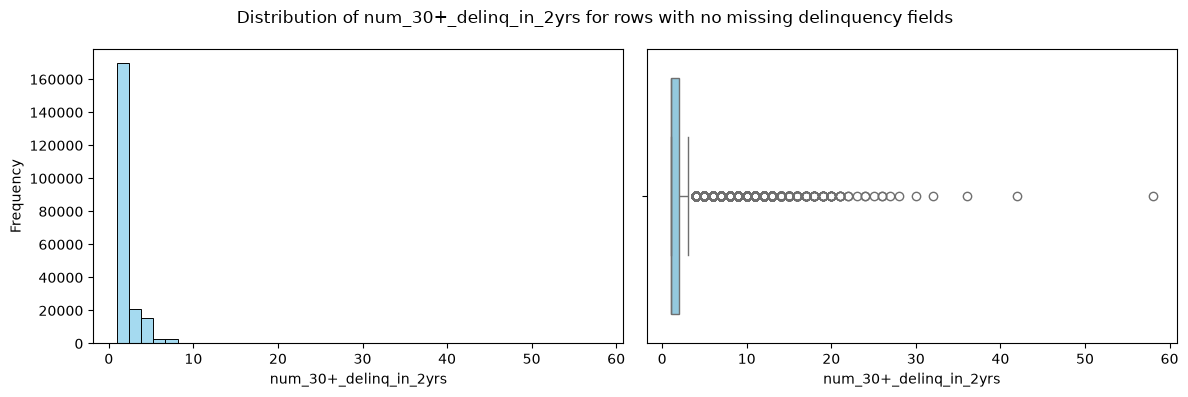

In [29]:
mask = (missing_count == 0) & (X[count_col] > 0)
plt.figure(figsize=(12, 4))
plt.subplot(1,2,1)
sns.histplot(X.loc[mask, count_col], bins=40, kde=False, color='skyblue', edgecolor='black')
plt.xlabel('num_30+_delinq_in_2yrs')
plt.ylabel('Frequency')

plt.subplot(1,2,2)
sns.boxplot(x=X.loc[mask, count_col], color='skyblue')
plt.xlabel('num_30+_delinq_in_2yrs')

plt.suptitle('Distribution of num_30+_delinq_in_2yrs for rows with no missing delinquency fields')
plt.tight_layout()
plt.show()

The hypothesis assessed here tried to determine that, when all the monthly delinquency variables are missing, the user has no delinquency event. Nevertheless, this last analysis shows that in some cases the number of +30 days delinquencies in the last 2 years reach even more than 55 cases although theses cases reprensent just 0.42 % of 1089830 users. 

Therefore, a new variable `without_recent_delinquency`could be used as 1 when the three monthly related variables are missing + `num_30+_delinq_in_2yrs` is null and 0 for the rest.

In [30]:
# Check missing values in string variables
missing_str_var = X[string_var].isnull().sum().sort_values(ascending=False) > 0
missing_str_var = missing_str_var[missing_str_var].index.tolist()
X[missing_str_var].isnull().sum().sort_values(ascending=False)

emp_title     148527
emp_length    130346
dtype: int64

In [31]:
# Check if emp_title is missing when emp_length is missing
mask = X["emp_length"].isna()

X.loc[mask, "emp_title"].isna().mean() * 100

np.float64(99.40542862841974)

For string variables, just the employment-related variables have missing values. The title has more missing values than the lenght so not all missing lengths can be considered as unemployed users

In [32]:
# Looking for possible labels for unemployed in the employment title variable
pattern = r"unemployed|jobless|not employed|out of work|laid off|no job|retired|homemaker|stay at home"
mask = X['emp_title'].str.contains(pattern, case=False, na=False)
Unemployed_titles = X[mask]['emp_title'].unique().tolist()
Unemployed_titles


['real estate agent and retired principal',
 'retired',
 'retired -  education specialist',
 'homemaker',
 'retired educator',
 'homemaker , tennihet',
 'pschytech / retired',
 'leased owner operator, retired us army',
 'golf course starter - retired vp',
 'teacher/ retired police officer',
 'contractor and retired us army',
 'retired dental assistant',
 'retired bus service manager',
 'realtor/ retired teacher',
 'retired teacher',
 'retired from state of california',
 'care giver/homemaker',
 'driver  cater driver  retired',
 'security guard/retired military',
 'homemaker /companion',
 'dealer / retired from us army',
 'retired/ substitute teacher',
 'sports referee & retired usps',
 'model/writer/spokesperson/retired educat',
 'probation officer/part time/ retired',
 'construction laborer/retired air force',
 'sales/retired',
 'teacher and retired administrator',
 'director retired educators',
 'xmas tree repair part time +retired',
 'teacher/army retired',
 'retired teacher now sub

Some descriptions related to the word `retired` or homemaker cannot be used to consider the user as some of them continue working as they are, for example, retired form US army but still working. Therefore it is difficult to use this variable to help the model as it is hard to generalize. An AI could be used here to determine based on the description if the user works or not

In [33]:
mask = X['emp_length'].isnull() & X['emp_title'].notnull()
X[mask]['emp_title'].head(20)

7383               motor vehicle rep
12073                          owner
26383                       employee
40103                         driver
40213                    team leader
43995                    floor sales
44422                 platoon leader
57015                         driver
64480                       employee
99637                         worker
102488                    contractor
122802                     secretary
147576                    bus driver
201823                        driver
202880            research assistant
209039                       retired
215274        retirement and pension
218339               retired teacher
228504    traffic control specialist
231201                       retired
Name: emp_title, dtype: str

From employment titles of missing values of the employment length it is not possible to know if a missing value reprents unemployment or, for instance, if users that have just started to work

In [34]:
# Crating a new dataframe to centralize variables with missing values 
missing_count = X[missing_num_var + missing_str_var].isnull().sum().sort_values(ascending=False)
missing_pct = (missing_count / X.shape[0] * 100).round(2)
type_var = X[missing_num_var + missing_str_var].dtypes

missing_df = pd.concat(
    [missing_count, missing_pct, type_var],
    axis=1,
    keys=['Missing Count', 'Missing (%)', 'Data Type']
)

display(missing_df)

,Missing Count,Missing (%),Data Type
mths_since_recent_bankcard_delinq,1643502,76.81,float64
mths_since_recent_revol_delinq,1433891,67.02,float64
mths_since_last_delinq,1090997,50.99,float64
mths_since_last_installment_acc_op,905256,42.31,float64
bal_to_cred_lim,865775,40.46,float64
num_inq,865656,40.46,float64
num_open_trades_in_6mths,865656,40.46,float64
num_installment_acc_op_in_12mths,865656,40.46,float64
num_rev_trades_op_in_12mths,865656,40.46,float64
num_installment_acc_op_in_24mths,865656,40.46,float64
